# What Former Employees Say: Final Analysis

# Summary

This notebook compares Glassdoor reviews from former and current employees in three ways: the rating gap, the signal in Cons text, and the number of reviews needed to trust an employer's gap. We use 4,950,343 employee reviews posted from 2020 onward. Former employees rate their employer 0.59 points lower than current employees of the same employer, which is close to the pooled gap of 0.50. Their Cons text tells them apart from current employees of the same employer and rating with an AUC of 0.628, and most of this signal remains after past and present verb forms are merged. An employer needs about 170 reviews in each group to estimate its gap within ±0.25, but only 7.0% of employers have this many. The gap is real and visible in text, but most employers do not have enough reviews to show it reliably.

| RQ | Question | Answer |
| :-- | :-- | :-- |
| RQ1 | Do former employees rate lower within the same employer? | Yes. −0.594 [−0.604, −0.583], close to the pooled −0.500 (H1 supported) |
| RQ2 | Does Cons text tell former from current employees? | Yes. AUC 0.628, and 0.593 after lemmatization; "management" in the top 20 (H2a, H2b supported) |
| RQ3 | How many reviews does an employer need? | 170 per group; only 7.0% of employers have them (H3 supported) |

We handled review skew per employer at each step of the analysis. Requiring at least 10 former and 10 current reviews removes 69.2% of employers but only 2.2% of reviews. We then average gaps and AUCs across employers with equal weight, so that a few large employers do not dominate, and compute CIs by resampling employers. For RQ2, we split the data by employer, and for RQ3 we report both the share of employers and the share of reviews. The RQ1 result keeps its direction for thresholds from 5 to 50 reviews, so our conclusions do not depend on the filter.

We tested sentence embeddings as an alternative to TF-IDF in Appendix A. With EmbeddingGemma embeddings and the same classifier and evaluation, the AUC was 0.605 [0.600, 0.610], which is 0.022 [0.018, 0.027] lower than TF-IDF. TF-IDF also shows which words drive the prediction, which H2b requires, and it costs much less to run. We therefore keep TF-IDF as the main model and report sentence embeddings as a comparison.

# 0. Setup

In [1]:
from google.colab import drive

drive.mount("/content/drive")

!pip install -q -r /content/drive/MyDrive/what-former-employees-say/requirements.txt

Mounted at /content/drive


In [2]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from google.colab import userdata
import nltk
from nltk.stem import WordNetLemmatizer
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from tqdm.std import tqdm

nltk.download("wordnet")

seed = 507

k_rq1 = 10
k_rq2 = 5
k_rq3 = 1000

data_dir = "/content/drive/MyDrive/what-former-employees-say/data/final-analysis"
raw_data_path = f"{data_dir}/raw/all_reviews 2.csv"
processed_path = f"{data_dir}/processed/processed.parquet"
rq2_train_embd_path = f"{data_dir}/processed/rq2/train_embd.npy"
rq2_val_embd_path = f"{data_dir}/processed/rq2/validation_embd.npy"
rq2_test_embd_path = f"{data_dir}/processed/rq2/test_embd.npy"

[nltk_data] Downloading package wordnet to /root/nltk_data...


# 1. Data Preparation

## 1.1 Load Raw Data

In [3]:
raw_df = pd.read_csv(raw_data_path, low_memory=False)
print(f"Data shape: {raw_df.shape}")

Data shape: (9901889, 19)


In [4]:
raw_df.head(5)

,rating,title,status,pros,cons,advice,Recommend,CEO Approval,Business Outlook,Career Opportunities,Compensation and Benefits,Senior Management,Work/Life Balance,Culture & Values,Diversity & Inclusion,firm_link,date,job,index
0,5.0,Good,"Current Employee, more than 10 years",Knowledge gain of complete project,Financial growth and personal growth,NaN,v,o,v,3,3,3,3,3.0,3.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Nov 19, 2022",Manager Design,NaN
1,4.0,Good,"Former Employee, less than 1 year","Good work,good work , flexible, support","Good,work, flexible,good support, good team work",NaN,v,o,o,4,4,4,4,4.0,4.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Jan 29, 2022",Anonymous Employee,NaN
2,4.0,"Supervising the manufacturing the processes, e...","Current Employee, more than 1 year",This company is a best opportunity for me to l...,"Monthly Target work,Maintain production schedu...",NaN,v,o,v,2,3,2,2,2.0,2.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Aug 12, 2021",Production Engineer,NaN
3,1.0,terrible,"Current Employee, more than 1 year",I wish there were some to list,too many to list here,NaN,x,x,x,1.0,3.0,1.0,3.0,1.0,NaN,https://www.glassdoor.com/Reviews/Calgary-Flam...,"Sep 24, 2020",Senior Account Executive,NaN
4,4.0,"It could be so good, but it isn’t","Current Employee, more than 3 years",Fast Paced. Endless challenges. Inclusive envi...,The biggest perk of the job provides no value ...,NaN,o,o,o,3.0,3.0,3.0,1.0,4.0,5.0,https://www.glassdoor.com/Reviews/Calgary-Flam...,"Mar 25, 2023",Assistant Manager,NaN


## 1.2 Duplicates and Missing Values

In [5]:
raw_df["firm_id"] = raw_df["firm_link"].str.extract(r"-Reviews-E(\d+)")[0]

n_before = len(raw_df)
raw_df = raw_df.drop_duplicates(subset=["title", "rating", "status", "pros", "cons", "firm_id", "date", "job"])
print(f"Before: {n_before:,}\nAfter: {len(raw_df):,}")

Before: 9,901,889
After: 9,466,241


In [6]:
# Create new columns
status = raw_df["status"].str.strip()
raw_df["former"] = status.str.extract(r"^(Current|Former) ")[0].map({"Current": 0, "Former": 1})
raw_df["emp_type"] = status.str.extract(r"^(?:Current|Former) ([^,]+)")[0]
raw_df["tenure"] = status.str.extract(r"(less than 1 year|more than \d+ years?)")[0]
raw_df["date"] = pd.to_datetime(raw_df["date"], errors="coerce")
raw_df["year"] = raw_df["date"].dt.year
raw_df["rating"] = pd.to_numeric(raw_df["rating"], errors="coerce")

In [7]:
print(raw_df[["firm_id", "rating", "former", "date", "cons"]].isna().sum())

firm_id      0
rating     157
former     368
date       157
cons       217
dtype: int64


In [8]:
n_before = len(raw_df)
raw_df = raw_df.dropna(subset=["firm_id", "rating", "former", "date", "cons"])
print(f"Before: {n_before:,}\nAfter: {len(raw_df):,}")

Before: 9,466,241
After: 9,465,813


## 1.3 Filtering

In [9]:
is_employee = raw_df["emp_type"] == "Employee"
is_recent = raw_df["year"] >= 2020
print(f"Not employee: {(~is_employee).sum():,} ({(~is_employee).mean() * 100:.1f}%)")
print(f"Before 2020: {(~is_recent).sum():,} ({(~is_recent).mean() * 100:.1f}%)")

Not employee: 9,568 (0.1%)
Before 2020: 4,510,019 (47.6%)


In [10]:
n_before = len(raw_df)
raw_df = raw_df[is_employee & is_recent]
print(f"Before: {n_before:,}\nAfter: {len(raw_df):,}")

Before: 9,465,813
After: 4,950,343


## 1.4 Save Processed Data

In [11]:
raw_df = raw_df[["firm_id", "rating", "former", "emp_type", "tenure", "year", "date", "cons"]]
raw_df = raw_df.astype({"firm_id": "int64", "rating": "int8", "former": "int8", "year": "int16"})
raw_df["emp_type"] = raw_df["emp_type"].astype("category")
raw_df["tenure"] = raw_df["tenure"].astype("category")

In [12]:
raw_df.to_parquet(processed_path, index=False)
print(f"Data shape: {raw_df.shape}")
print(raw_df.dtypes)

Data shape: (4950343, 8)
firm_id              int64
rating                int8
former                int8
emp_type          category
tenure            category
year                 int16
date        datetime64[ns]
cons                object
dtype: object


# 2. EDA

In [13]:
# Load processed data
df = pd.read_parquet(processed_path)

## 2.1 Status


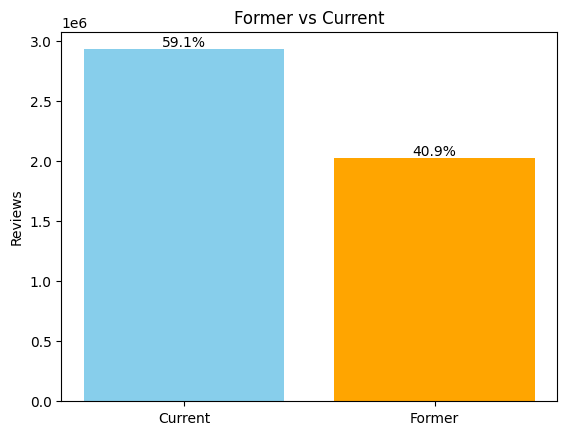

In [14]:
status_counts = df["former"].map({1: "Former", 0: "Current"}).value_counts().reindex(["Current", "Former"])
status_pct = status_counts / status_counts.sum() * 100
colors = ["skyblue", "orange"]

status_bars = plt.bar(status_counts.index, status_counts.values, color=colors)
plt.bar_label(status_bars, labels=[f"{p:.1f}%" for p in status_pct])
plt.title("Former vs Current")
plt.ylabel("Reviews")

plt.show()

## 2.2 Rating

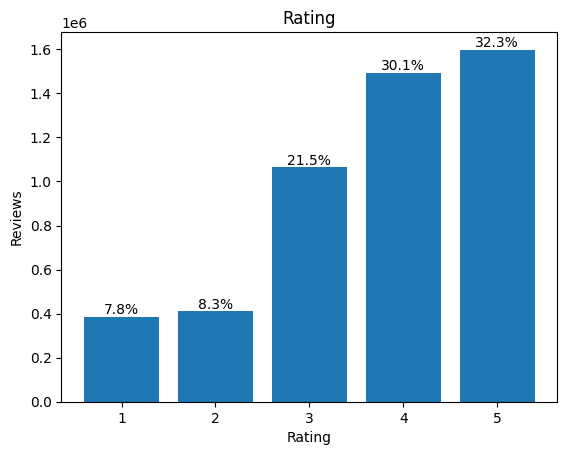

In [15]:
rating_counts = df["rating"].value_counts().sort_index()
rating_pct = rating_counts / rating_counts.sum() * 100

rating_bars = plt.bar(rating_counts.index, rating_counts.values)
plt.bar_label(rating_bars, labels=[f"{p:.1f}%" for p in rating_pct])
plt.title("Rating")
plt.xlabel("Rating")
plt.ylabel("Reviews")

plt.show()

## 2.3 Cons Length

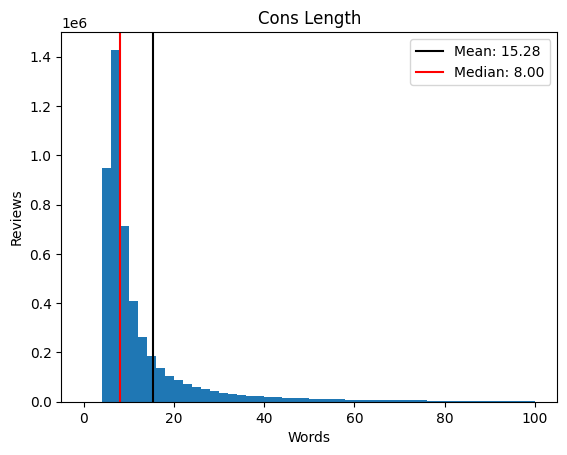

In [16]:
cons_len = df["cons"].str.split().str.len()

plt.hist(cons_len, bins=50, range=(0, 100))
plt.axvline(x=cons_len.mean(), color="black", label=f"Mean: {cons_len.mean():.2f}")
plt.axvline(x=cons_len.median(), color="red", label=f"Median: {cons_len.median():.2f}")
plt.title("Cons Length")
plt.xlabel("Words")
plt.ylabel("Reviews")

plt.legend()
plt.show()

## 2.4 Reviews per Employer

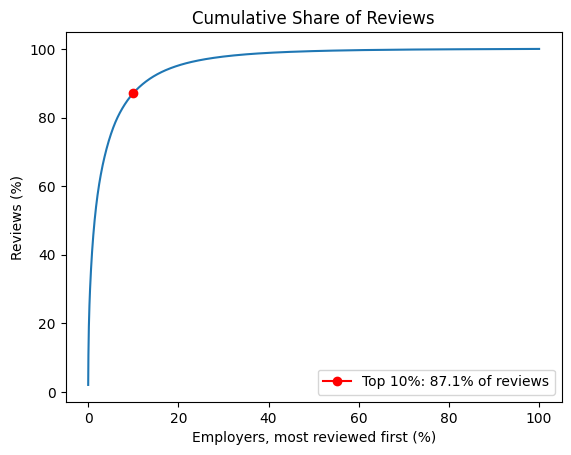

In [17]:
per_firm = df["firm_id"].value_counts()

review_share = per_firm.cumsum().to_numpy() / per_firm.sum() * 100
employer_share = np.arange(1, len(per_firm) + 1) / len(per_firm) * 100
top10_share = review_share[employer_share <= 10][-1]

plt.plot(employer_share, review_share)
plt.plot(10, top10_share, marker="o", color="red", label=f"Top 10%: {top10_share:.1f}% of reviews")
plt.title("Cumulative Share of Reviews")
plt.xlabel("Employers, most reviewed first (%)")
plt.ylabel("Reviews (%)")

plt.legend()
plt.show()

## 2.5 Top Words

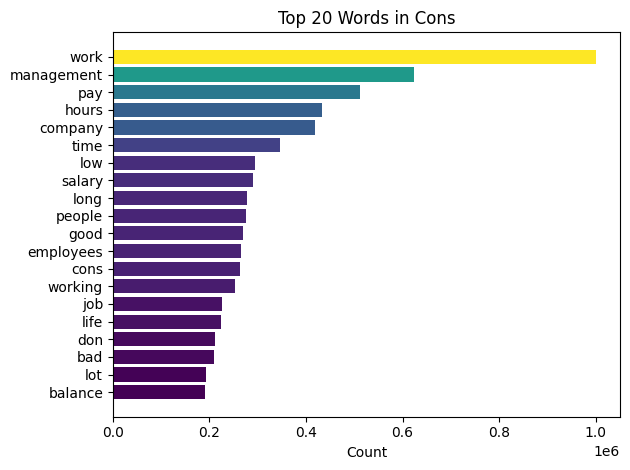

In [18]:
def top_words(series: pd.Series, n: int = 20) -> list[tuple[str, int]]:
    """Return the n most common words in the series, excluding stop words and single letters.

    Args:
        series (pd.Series): Texts to count words in
        n (int, optional): Number of words to return

    Returns:
        list[tuple[str, int]]: (word, count) pairs, most common first
    """
    counter = Counter()
    for tokens in series.dropna().str.lower().str.findall(r"[a-z]+"):
        counter.update(w for w in tokens if len(w) > 1 and w not in ENGLISH_STOP_WORDS)
    return counter.most_common(n)

words, counts = zip(*top_words(df["cons"])[::-1])

norm = plt.Normalize(min(counts), max(counts))
colors = plt.cm.viridis(norm(counts))

plt.barh(words, counts, color=colors)
plt.title("Top 20 Words in Cons")
plt.xlabel("Count")
plt.tight_layout()

plt.show()

## 2.6 Sample per Research Question

In [19]:
def filter_employers(df: pd.DataFrame, k: int) -> pd.DataFrame:
    """Keep reviews from employers with at least k former and k current reviews.

    Args:
        df (pd.DataFrame): Reviews with firm_id and former columns
        k (int): Minimum number of reviews in each group

    Returns:
        pd.DataFrame: Reviews from employers that meet the threshold
    """
    counts = df.groupby(["firm_id", "former"]).size().unstack(fill_value=0)
    keep = counts[counts.min(axis=1) >= k].index
    return df[df["firm_id"].isin(keep)]

rows = []

for rq, k in [("RQ1", k_rq1), ("RQ2", k_rq2), ("RQ3", k_rq3)]:
    sample = filter_employers(df, k)
    rows.append({
        "RQ": rq,
        "k": k,
        "Employers": sample["firm_id"].nunique(),
        "Employers (%)": sample["firm_id"].nunique() / df["firm_id"].nunique() * 100,
        "Reviews": len(sample),
        "Reviews (%)": len(sample) / len(df) * 100,
    })

pd.DataFrame(rows).round(1)

,RQ,k,Employers,Employers (%),Reviews,Reviews (%)
0,RQ1,10,8539,30.8,4842080,97.8
1,RQ2,5,10979,39.6,4889269,98.8
2,RQ3,1000,333,1.2,2294682,46.4


# 3. RQ1: Rating Gap

## 3.1 Pooled Baseline

In [20]:
rq1_pooled_means = df.groupby("former")["rating"].mean()
rq1_pooled_gap = rq1_pooled_means[1] - rq1_pooled_means[0]

print(f"Pooled gap: {rq1_pooled_gap:.3f}")

Pooled gap: -0.500


## 3.2 Within-Employer Gap

In [21]:
def employer_gaps(df: pd.DataFrame, k: int) -> pd.Series:
    """Return each employer's rating gap (former mean minus current mean).

    Args:
        df (pd.DataFrame): Reviews with firm_id, former and rating columns
        k (int): Minimum number of former and current reviews per employer

    Returns:
        pd.Series: Gap per employer, indexed by firm_id
    """
    means = filter_employers(df, k).pivot_table(index="firm_id", columns="former", values="rating", aggfunc="mean")
    return means[1] - means[0]

def bootstrap_ci(values: pd.Series, seed: int, n: int = 2000) -> np.ndarray:
    """Return the 95% percentile bootstrap CI of the mean, resampling employers.

    Args:
        values (pd.Series): One value per employer
        seed (int): Random seed
        n (int, optional): Number of bootstrap samples

    Returns:
        np.ndarray: Lower and upper bounds of the CI
    """
    rng = np.random.default_rng(seed)
    x = values.to_numpy()
    means = [rng.choice(x, size=len(x)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

In [22]:
rq1_gaps = employer_gaps(df, k_rq1)
rq1_gap_mean = rq1_gaps.mean()
rq1_lo, rq1_hi = bootstrap_ci(rq1_gaps, seed)

print(f"Employers: {len(rq1_gaps):,}")
print(f"Within-employer gap: {rq1_gap_mean:.3f} [{rq1_lo:.3f}, {rq1_hi:.3f}]")

Employers: 8,539
Within-employer gap: -0.594 [-0.604, -0.583]


## 3.3 Result

In [23]:
print(f"Difference from pooled gap: {rq1_gap_mean - rq1_pooled_gap:.3f}")
print(f"H1 - CI below 0: {rq1_hi < 0}, |gap| >= 0.25: {abs(rq1_gap_mean) >= 0.25}")
print(f"Different from pooled (|diff| >= 0.25): {abs(rq1_gap_mean - rq1_pooled_gap) >= 0.25}")

Difference from pooled gap: -0.094
H1 - CI below 0: True, |gap| >= 0.25: True
Different from pooled (|diff| >= 0.25): False


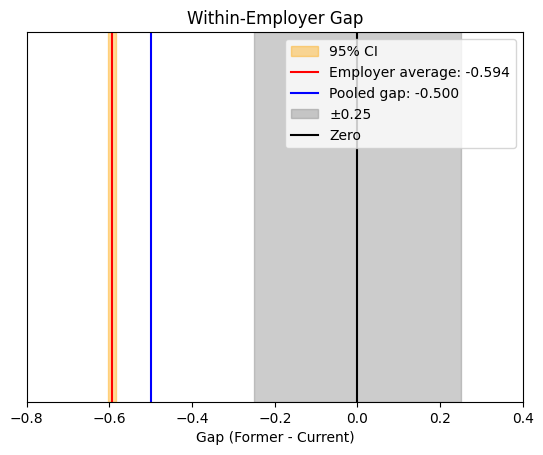

In [24]:
plt.axvspan(rq1_lo, rq1_hi, color="orange", alpha=0.4, label="95% CI")
plt.axvline(rq1_gap_mean, color="red", label=f"Employer average: {rq1_gap_mean:.3f}")
plt.axvline(rq1_pooled_gap, color="blue", label=f"Pooled gap: {rq1_pooled_gap:.3f}")
plt.axvspan(-0.25, 0.25, color="gray", alpha=0.4, label="±0.25")
plt.axvline(0, color="black", label="Zero")
plt.xlim(-0.8, 0.4)
plt.title("Within-Employer Gap")
plt.xlabel("Gap (Former - Current)")
plt.yticks([])

plt.legend()
plt.show()

## 3.4 Robustness

### Review Threshold

In [25]:
rows = []
for k in [5, 10, 20, 50]:
    gaps = employer_gaps(df, k)
    lower, upper = bootstrap_ci(gaps, seed)
    rows.append({
        "k": k,
        "Employers": len(gaps),
        "Gap": gaps.mean(),
        "CI Lower": lower,
        "CI Upper": upper,
        "Diff from Pooled": gaps.mean() - rq1_pooled_gap,
    })

rq1_threshold = pd.DataFrame(rows)
rq1_threshold.round(3)

,k,Employers,Gap,CI Lower,CI Upper,Diff from Pooled
0,5,10979,-0.620,-0.631,-0.609,-0.120
1,10,8539,-0.594,-0.604,-0.583,-0.094
2,20,6495,-0.561,-0.571,-0.550,-0.061
3,50,4195,-0.513,-0.523,-0.502,-0.013


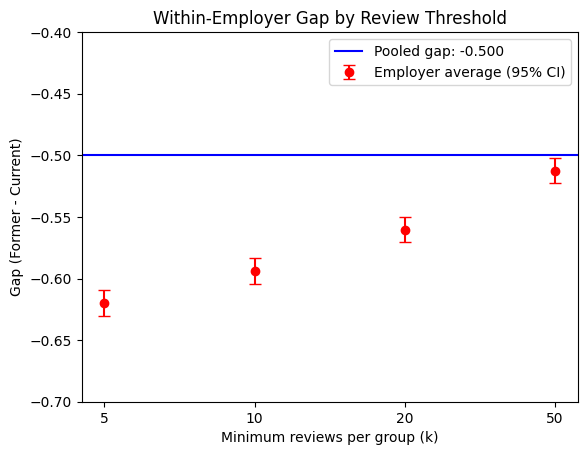

In [26]:
plt.errorbar(
    rq1_threshold["k"].astype(str),
    rq1_threshold["Gap"],
    yerr=[rq1_threshold["Gap"] - rq1_threshold["CI Lower"], rq1_threshold["CI Upper"] - rq1_threshold["Gap"]],
    fmt="o",
    color="red",
    capsize=4,
    label="Employer average (95% CI)",
)
plt.axhline(rq1_pooled_gap, color="blue", label=f"Pooled gap: {rq1_pooled_gap:.3f}")
plt.ylim(-0.7, -0.4)
plt.title("Within-Employer Gap by Review Threshold")
plt.xlabel("Minimum reviews per group (k)")
plt.ylabel("Gap (Former - Current)")

plt.legend()
plt.show()

### Tenure Bands

In [27]:
tenure_order = ["less than 1 year", "more than 1 year", "more than 3 years", "more than 5 years", "more than 8 years", "more than 10 years"]

print(f"Missing tenure: {df["tenure"].isna().sum():,} ({df["tenure"].isna().mean() * 100:.1f}%)")

Missing tenure: 1,965,767 (39.7%)


In [28]:
rows = []
for tenure in tenure_order:
    gaps = employer_gaps(df[df["tenure"] == tenure], k_rq1)
    lower, upper = bootstrap_ci(gaps, seed)
    rows.append({
        "Tenure": tenure,
        "Employers": len(gaps),
        "Gap": gaps.mean(),
        "CI Lower": lower,
        "CI Upper": upper,
        "Diff from Pooled": gaps.mean() - rq1_pooled_gap,
    })

rq1_tenure = pd.DataFrame(rows)
rq1_tenure.round(3)

,Tenure,Employers,Gap,CI Lower,CI Upper,Diff from Pooled
0,less than 1 year,3081,-0.746,-0.765,-0.727,-0.246
1,more than 1 year,4107,-0.534,-0.549,-0.520,-0.035
2,more than 3 years,3382,-0.444,-0.458,-0.430,0.055
3,more than 5 years,2297,-0.447,-0.465,-0.430,0.053
4,more than 8 years,1316,-0.410,-0.432,-0.388,0.090
5,more than 10 years,1172,-0.460,-0.487,-0.433,0.040


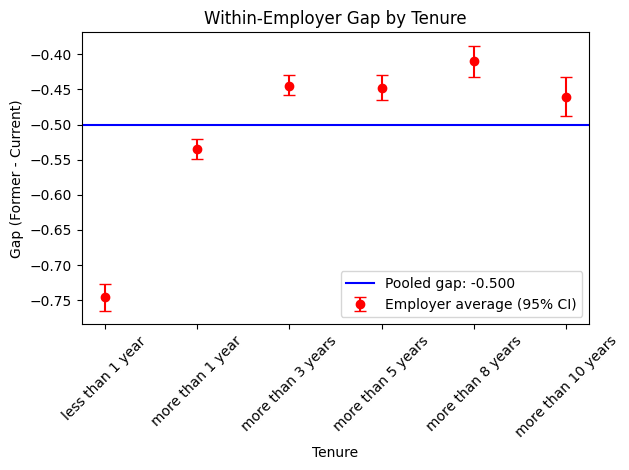

In [29]:
plt.errorbar(
    rq1_tenure["Tenure"],
    rq1_tenure["Gap"],
    yerr=[rq1_tenure["Gap"] - rq1_tenure["CI Lower"], rq1_tenure["CI Upper"] - rq1_tenure["Gap"]],
    fmt="o",
    color="red",
    capsize=4,
    label="Employer average (95% CI)",
)
plt.axhline(rq1_pooled_gap, color="blue", label=f"Pooled gap: {rq1_pooled_gap:.3f}")
plt.title("Within-Employer Gap by Tenure")
plt.xlabel("Tenure")
plt.ylabel("Gap (Former - Current)")
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

# 4. RQ2: Text Signal

## 4.1 Data Preparation

In [30]:
rq2_df = filter_employers(df, k_rq2)

def group_split(df: pd.DataFrame, col: str, test_size: float, seed: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split reviews into two sets so that no group appears in both.

    Args:
        df (pd.DataFrame): Reviews to split
        col (str): Name of the group column
        test_size (float): Share of groups in the second set
        seed (int): Random seed

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: First and second set
    """
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(df, groups=df[col]))
    return df.iloc[a].copy(), df.iloc[b].copy()

# Split sample to train/validation/test (64%/16%/20%)
trainval, test = group_split(rq2_df, "firm_id", 0.20, seed)
train, val = group_split(trainval, "firm_id", 0.20, seed)

print(f"<Dataset Share>\nTrain     : {len(train) / len(rq2_df) * 100:.2f}%\nValidation: {len(val) / len(rq2_df) * 100:.2f}%\nTest      : {len(test) / len(rq2_df) * 100:.2f}%\n\n")
print(f"<Average Ratings>\nTrain     : {train["rating"].mean():.2f}\nValidation: {val["rating"].mean():.2f}\nTest      : {test["rating"].mean():.2f}")

<Dataset Share>
Train     : 65.53%
Validation: 14.88%
Test      : 19.59%


<Average Ratings>
Train     : 3.70
Validation: 3.71
Test      : 3.73


In [31]:
def phrase_table(df: pd.DataFrame, col: str, seed: int, n: int = 300000) -> pd.DataFrame:
    """Return the 20 phrases most typical of former reviews and of current reviews.

    Args:
        df (pd.DataFrame): Reviews with former and the text column
        col (str): Name of the text column
        seed (int): Random seed for sampling
        n (int, optional): Number of reviews to sample

    Returns:
        pd.DataFrame: Top 20 phrases and their former/current ratio for each side
    """
    sample = df.sample(n, random_state=seed)
    former_text = sample.loc[sample["former"] == 1, col]
    current_text = sample.loc[sample["former"] == 0, col]

    cv = CountVectorizer(ngram_range=(1, 3), min_df=20, binary=True, token_pattern=r"(?u)\b\w+\b")
    cv.fit(sample[col])

    table = pd.DataFrame({
        "phrase": cv.get_feature_names_out(),
        "former_pct": np.asarray(cv.transform(former_text).sum(axis=0)).ravel() / len(former_text) * 100,
        "current_pct": np.asarray(cv.transform(current_text).sum(axis=0)).ravel() / len(current_text) * 100,
    })
    table["ratio"] = (table["former_pct"] + 0.01) / (table["current_pct"] + 0.01)

    former_side = table.sort_values("ratio", ascending=False).head(20)[["phrase", "ratio"]]
    current_side = table.sort_values("ratio").head(20)[["phrase", "ratio"]]
    return pd.concat([former_side.reset_index(drop=True), current_side.reset_index(drop=True)], axis=1, keys=["former", "current"])

phrase_table(train, "cons", seed)

former                  current          
            phrase     ratio         phrase     ratio
0           i left  7.628042       till now  0.150921
1      i was there  7.526938       cons yet  0.172004
2   management was  6.773458         so far  0.173754
3        was there  6.504055    none so far  0.177533
4    managers were  6.177765        none so  0.180968
5           seemed  6.053467    cons so far  0.208363
6   i worked there  6.045882      as of now  0.209227
7         pay wasn  6.025258         of yet  0.210457
8       pay wasn t  6.025258          as of  0.212617
9        was awful  5.913409      as of yet  0.212753
10          i quit  5.871047         of now  0.213289
11   there were no  5.696096       so far i  0.214684
12        i worked  5.662917   any cons yet  0.215674
13    was terrible  5.655269        cons so  0.219228
14     i worked at  5.612499  haven t found  0.233011
15       felt like  5.602581         i love  0.235367
16        were not  5.580440          far i  0.235855
17         were no  5.530353    will update  0.237553
18      hours were  5.510615     no cons so  0.246762
19   my time there  5.506812         i work  0.247604

### Signals

| former | current |
| :----- | :------ |
| i left, i quit, i worked, i worked at, i worked there, i was there, was there, my time there, i was working, was working | i work, haven't found, will update, till now, so far, so far i, far i, cons yet, any cons yet, cons so, cons so far, none so, none so far, none as of, any so far, any yet, as of, as of now, as of yet, of now |

In [32]:
remove_phrases = [
    "i left", "i quit", "i worked", "i worked at", "i worked there", "i was there", "was there", "my time there", "i was working", "was working",
    "i work", "haven't found", "will update",
    "till now", "so far", "so far i", "far i", "cons yet", "any cons yet", "cons so", "cons so far", "none so", "none so far", "none as of",
    "any so far", "any yet", "as of", "as of now", "as of yet", "of now",
]
pattern = r"\b(" + "|".join(p.replace("'", "['’]?") for p in sorted(remove_phrases, key=len, reverse=True)) + r")\b"

def remove_signals(text: pd.Series) -> pd.Series:
    """Remove phrases that state employment status outright.

    Args:
        text (pd.Series): Cons texts

    Returns:
        pd.Series: Texts with the status phrases replaced by a space
    """
    return text.str.replace(pattern, " ", case=False, regex=True)

train["cons_clean"] = remove_signals(train["cons"])
val["cons_clean"] = remove_signals(val["cons"])
test["cons_clean"] = remove_signals(test["cons"])

## 4.2 Baseline: Word Count

In [33]:
# AUC Score
def employer_auc(test_data: pd.DataFrame, y_pred: np.ndarray) -> pd.Series:
    """Return the AUC per employer, using former/current pairs with the same rating.

    Args:
        test_data (pd.DataFrame): Reviews with firm_id, rating and former columns
        y_pred (np.ndarray): Predicted probability of being former, one per review

    Returns:
        pd.Series: AUC per employer, indexed by firm_id (employers without pairs are dropped)
    """
    df = test_data.copy()
    df["pred"] = y_pred
    records = []

    for (firm, rating), g in df.groupby(["firm_id", "rating"]):
        f_preds = np.array(g[g["former"] == 1]["pred"])
        c_preds = np.array(g[g["former"] == 0]["pred"])

        if len(f_preds) == 0 or len(c_preds) == 0:
            continue

        diff = f_preds[:, np.newaxis] - c_preds
        wins = (diff > 0).sum() + 0.5 * (diff == 0).sum()
        pairs = len(f_preds) * len(c_preds)

        records.append({"firm_id": firm, "wins": wins, "pairs": pairs})

    result = pd.DataFrame(records)
    wins_sum = result.groupby("firm_id")["wins"].sum()
    pairs_sum = result.groupby("firm_id")["pairs"].sum()
    firm_auc = wins_sum / pairs_sum
    return firm_auc

def calculate_auc_score(test_data: pd.DataFrame, y_pred: np.ndarray) -> float:
    """Return the AUC averaged across employers with equal weight.

    Args:
        test_data (pd.DataFrame): Reviews with firm_id, rating and former columns
        y_pred (np.ndarray): Predicted probability of being former, one per review

    Returns:
        float: Mean of the employer AUCs
    """
    return employer_auc(test_data, y_pred).mean()

In [34]:
train["word_count"] = train["cons_clean"].str.split().str.len()
val["word_count"] = val["cons_clean"].str.split().str.len()
test["word_count"] = test["cons_clean"].str.split().str.len()

In [35]:
# Scale inputs since the range of words is large
ss = StandardScaler()

X_train_scaled = ss.fit_transform(train[["word_count"]])
X_val_scaled = ss.transform(val[["word_count"]])
X_test_scaled = ss.transform(test[["word_count"]])

In [36]:
lr_wc = LogisticRegression(max_iter=1000, random_state=seed)
model_wc = lr_wc.fit(X_train_scaled, train["former"])

## 4.3 TF-IDF Model

In [37]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=10)

X_train_tfidf = vectorizer.fit_transform(train["cons_clean"])
X_val_tfidf = vectorizer.transform(val["cons_clean"])
X_test_tfidf = vectorizer.transform(test["cons_clean"])

In [38]:
c_list = [0.01, 0.1, 1, 10]
val_auc_list = []

for c in c_list:
    lr_tfidf = LogisticRegression(C=c, max_iter=1000, random_state=seed)
    model_tfidf = lr_tfidf.fit(X_train_tfidf, train["former"])

    y_pred_tfidf = model_tfidf.predict_proba(X_val_tfidf)[:, 1] # Probability of Class 1 (former)
    val_auc = calculate_auc_score(val, y_pred_tfidf)
    print(f"C: {c} Validation AUC: {val_auc:.3f}\n")
    val_auc_list.append([c, val_auc])

best_c_tfidf, best_val_auc = max(val_auc_list, key=lambda x: x[1])
print(f"================================\nBest C: {best_c_tfidf} Validation AUC: {best_val_auc:.3f}")

C: 0.01 Validation AUC: 0.618

C: 0.1 Validation AUC: 0.634

C: 1 Validation AUC: 0.628

C: 10 Validation AUC: 0.621

Best C: 0.1 Validation AUC: 0.634


In [39]:
lr_tfidf = LogisticRegression(C=best_c_tfidf, max_iter=1000, random_state=seed)
model_tfidf = lr_tfidf.fit(X_train_tfidf, train["former"])

## 4.4 Evaluation

In [40]:
y_pred_wc = model_wc.predict_proba(X_test_scaled)[:, 1]
y_pred_tfidf = model_tfidf.predict_proba(X_test_tfidf)[:, 1]

rq2_employer_auc_wc = employer_auc(test, y_pred_wc)
rq2_employer_auc_tfidf = employer_auc(test, y_pred_tfidf)

rq2_auc_wc = rq2_employer_auc_wc.mean()
rq2_lo_wc, rq2_hi_wc = bootstrap_ci(rq2_employer_auc_wc, seed)
rq2_auc_tfidf = rq2_employer_auc_tfidf.mean()
rq2_lo_tfidf, rq2_hi_tfidf = bootstrap_ci(rq2_employer_auc_tfidf, seed)
rq2_lo_diff, rq2_hi_diff = bootstrap_ci(rq2_employer_auc_tfidf - rq2_employer_auc_wc, seed)

print(f"Employers with pairs: {len(rq2_employer_auc_tfidf):,} of {test["firm_id"].nunique():,}")
print(f"Word Count AUC: {rq2_auc_wc:.3f} [{rq2_lo_wc:.3f}, {rq2_hi_wc:.3f}]")
print(f"TF-IDF AUC: {rq2_auc_tfidf:.3f} [{rq2_lo_tfidf:.3f}, {rq2_hi_tfidf:.3f}]")
print(f"Difference (TF-IDF - Word Count): {rq2_auc_tfidf - rq2_auc_wc:.3f} [{rq2_lo_diff:.3f}, {rq2_hi_diff:.3f}]")

Employers with pairs: 2,194 of 2,196
Word Count AUC: 0.502 [0.497, 0.507]
TF-IDF AUC: 0.628 [0.622, 0.633]
Difference (TF-IDF - Word Count): 0.126 [0.118, 0.133]


## 4.5 Top Words

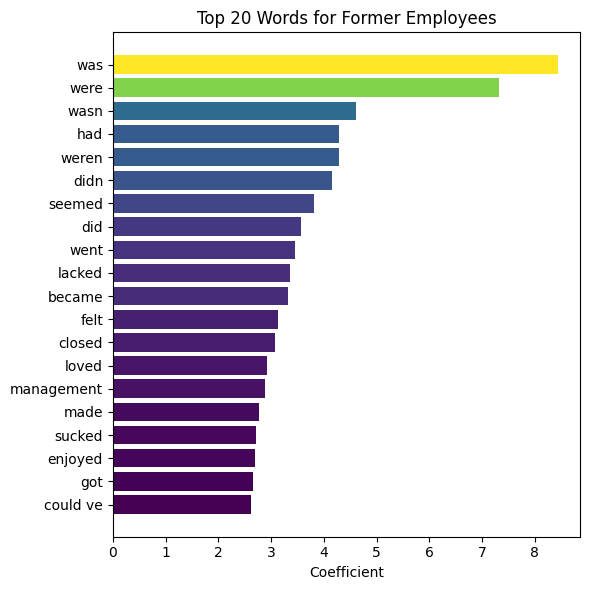

Rank of management: 15


In [41]:
feature_names = vectorizer.get_feature_names_out()
coefficients = model_tfidf.coef_[0]

rq2_importance = pd.DataFrame(
    {"word": feature_names, "coefficient": coefficients}
).sort_values(by="coefficient", ascending=False)

top20 = rq2_importance.head(20).iloc[::-1]

norm = plt.Normalize(top20["coefficient"].min(), top20["coefficient"].max())
colors = plt.cm.viridis(norm(top20["coefficient"]))

plt.figure(figsize=(6, 6))
plt.barh(top20["word"], top20["coefficient"], color=colors)
plt.xlabel("Coefficient")
plt.title("Top 20 Words for Former Employees")
plt.tight_layout()

plt.show()

rq2_management_rank = rq2_importance["word"].tolist().index("management") + 1
print(f"Rank of management: {rq2_management_rank}")

## 4.6 Result

In [42]:
print(f"H2a - TF-IDF AUC CI excludes 0.5: {rq2_lo_tfidf > 0.5}")
print(f"TF-IDF beats Word Count (difference CI above 0): {rq2_lo_diff > 0}")
print(f"H2b - management in top 20: {rq2_management_rank <= 20} (rank {rq2_management_rank})")


H2a - TF-IDF AUC CI excludes 0.5: True
TF-IDF beats Word Count (difference CI above 0): True
H2b - management in top 20: True (rank 15)


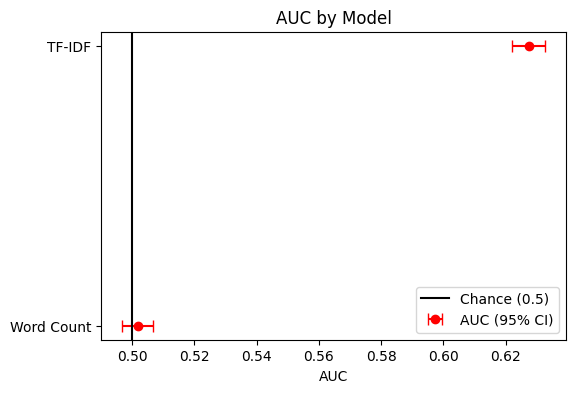

In [43]:
rq2_result = pd.DataFrame({
    "Model": ["Word Count", "TF-IDF"],
    "AUC": [rq2_auc_wc, rq2_auc_tfidf],
    "CI Lower": [rq2_lo_wc, rq2_lo_tfidf],
    "CI Upper": [rq2_hi_wc, rq2_hi_tfidf],
})

plt.figure(figsize=(6, 4))
plt.errorbar(
    rq2_result["AUC"],
    rq2_result["Model"],
    xerr=[rq2_result["AUC"] - rq2_result["CI Lower"], rq2_result["CI Upper"] - rq2_result["AUC"]],
    fmt="o",
    color="red",
    capsize=4,
    label="AUC (95% CI)",
)
plt.axvline(0.5, color="black", label="Chance (0.5)")
plt.title("AUC by Model")
plt.xlabel("AUC")

plt.legend()
plt.show()

## 4.7 Robustness

### Past Tense

In [44]:
lemmatizer = WordNetLemmatizer()
lemma_map = {w: lemmatizer.lemmatize(w, pos="v") for w in vectorizer.get_feature_names_out() if " " not in w}
lemma_map.update({
    "wasn": "isn", "weren": "isn", "aren": "isn", "didn": "don", "doesn": "don", "hadn": "haven", "hasn": "haven",
    "wasnt": "isnt", "werent": "isnt", "didnt": "dont", "hadnt": "havent",
    "would": "will", "wouldn": "won", "wouldnt": "wont", "could": "can", "couldn": "can", "couldnt": "cant",
    "felt": "feel", "saw": "see", "fell": "fall",
})

def to_lemma(text: pd.Series) -> pd.Series:
    """Replace each word with its verb lemma so that past and present forms look the same.

    Args:
        text (pd.Series): Cons texts with status phrases removed

    Returns:
        pd.Series: Lowercased texts with verbs in their base form
    """
    return text.str.lower().str.replace(r"\b\w\w+\b", lambda m: lemma_map.get(m.group(0), m.group(0)), regex=True)

train["cons_lemma"] = to_lemma(train["cons_clean"])
val["cons_lemma"] = to_lemma(val["cons_clean"])
test["cons_lemma"] = to_lemma(test["cons_clean"])

print({w: lemma_map[w] for w in ["was", "were", "had", "did", "went", "lacked", "felt", "management"]})

{'was': 'be', 'were': 'be', 'had': 'have', 'did': 'do', 'went': 'go', 'lacked': 'lack', 'felt': 'feel', 'management': 'management'}


In [45]:
vectorizer_lemma = TfidfVectorizer(ngram_range=(1, 2), min_df=10)

X_train_lemma = vectorizer_lemma.fit_transform(train["cons_lemma"])
X_val_lemma = vectorizer_lemma.transform(val["cons_lemma"])
X_test_lemma = vectorizer_lemma.transform(test["cons_lemma"])

val_auc_list_lemma = []

for c in c_list:
    lr_lemma = LogisticRegression(C=c, max_iter=1000, random_state=seed)
    model_lemma = lr_lemma.fit(X_train_lemma, train["former"])

    y_pred_lemma = model_lemma.predict_proba(X_val_lemma)[:, 1]
    val_auc = calculate_auc_score(val, y_pred_lemma)
    print(f"C: {c} Validation AUC: {val_auc:.3f}\n")
    val_auc_list_lemma.append([c, val_auc])

best_c_lemma, best_val_auc_lemma = max(val_auc_list_lemma, key=lambda x: x[1])
print(f"================================\nBest C: {best_c_lemma} Validation AUC: {best_val_auc_lemma:.3f}")

C: 0.01 Validation AUC: 0.583

C: 0.1 Validation AUC: 0.598

C: 1 Validation AUC: 0.594

C: 10 Validation AUC: 0.595

Best C: 0.1 Validation AUC: 0.598


In [46]:
lr_lemma = LogisticRegression(C=best_c_lemma, max_iter=1000, random_state=seed)
model_lemma = lr_lemma.fit(X_train_lemma, train["former"])

y_pred_lemma = model_lemma.predict_proba(X_test_lemma)[:, 1]
rq2_employer_auc_lemma = employer_auc(test, y_pred_lemma)
rq2_auc_lemma = rq2_employer_auc_lemma.mean()
rq2_lo_lemma, rq2_hi_lemma = bootstrap_ci(rq2_employer_auc_lemma, seed)
rq2_lo_diff_lemma, rq2_hi_diff_lemma = bootstrap_ci(rq2_employer_auc_lemma - rq2_employer_auc_tfidf, seed)

print(f"Lemmatized TF-IDF AUC: {rq2_auc_lemma:.3f} [{rq2_lo_lemma:.3f}, {rq2_hi_lemma:.3f}]")
print(f"Difference (Lemmatized - TF-IDF): {rq2_auc_lemma - rq2_auc_tfidf:.3f} [{rq2_lo_diff_lemma:.3f}, {rq2_hi_diff_lemma:.3f}]")

Lemmatized TF-IDF AUC: 0.593 [0.587, 0.598]
Difference (Lemmatized - TF-IDF): -0.035 [-0.039, -0.031]


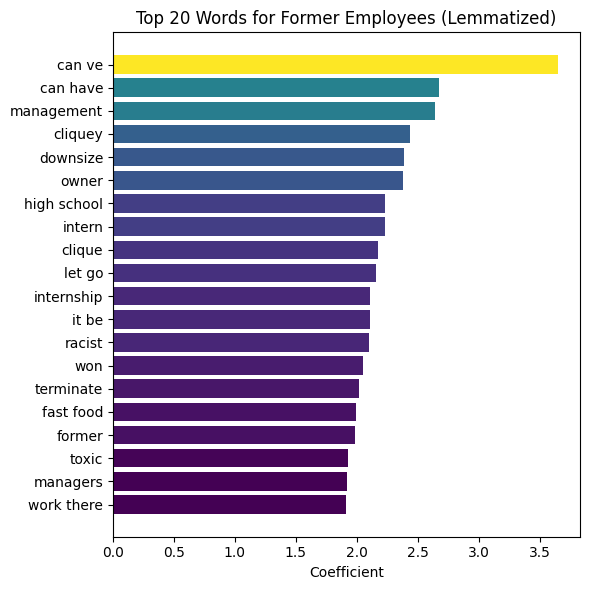

Rank of management: 3


In [47]:
rq2_importance_lemma = pd.DataFrame(
    {"word": vectorizer_lemma.get_feature_names_out(), "coefficient": model_lemma.coef_[0]}
).sort_values(by="coefficient", ascending=False)

top20 = rq2_importance_lemma.head(20).iloc[::-1]

norm = plt.Normalize(top20["coefficient"].min(), top20["coefficient"].max())
colors = plt.cm.viridis(norm(top20["coefficient"]))

plt.figure(figsize=(6, 6))
plt.barh(top20["word"], top20["coefficient"], color=colors)
plt.xlabel("Coefficient")
plt.title("Top 20 Words for Former Employees (Lemmatized)")
plt.tight_layout()

plt.show()

rq2_management_rank_lemma = rq2_importance_lemma["word"].tolist().index("management") + 1
print(f"Rank of management: {rq2_management_rank_lemma}")

In [48]:
print(f"H2a (lemmatized) - AUC CI excludes 0.5: {rq2_lo_lemma > 0.5}")
print(f"H2b (lemmatized) - management in top 20: {rq2_management_rank_lemma <= 20} (rank {rq2_management_rank_lemma})")

H2a (lemmatized) - AUC CI excludes 0.5: True
H2b (lemmatized) - management in top 20: True (rank 3)


# 5. RQ3: Reviews Needed

## 5.1 Baseline: Normal Approximation

In [49]:
def normal_n_star(sd: float, tolerance: float, z: float) -> int:
    """Return n* per group from the normal approximation for a difference of two means.

    Args:
        sd (float): Standard deviation of ratings
        tolerance (float): Allowed error of the gap
        z (float): z value of the confidence level

    Returns:
        int: Number of reviews needed in each group
    """
    return int(np.ceil(2 * (z * sd / tolerance) ** 2))

rq3_sd_all = df["rating"].std()
rq3_n_star_normal = normal_n_star(rq3_sd_all, 0.25, 1.96)

print(f"All reviews SD: {rq3_sd_all:.2f}, n* per group: {rq3_n_star_normal}")

All reviews SD: 1.22, n* per group: 183


## 5.2 Resampling

In [50]:
def calculate_reference_gap(df: pd.DataFrame) -> float:
    """Return an employer's gap from all its reviews (former mean minus current mean).

    Args:
        df (pd.DataFrame): Reviews of one employer

    Returns:
        float: Reference gap
    """
    s = df.groupby("former")["rating"].mean()
    return s.loc[1] - s.loc[0]

def calculate_sample_gap(f: np.ndarray, c: np.ndarray, n: int, rng: np.random.Generator) -> float:
    """Return the gap from n former and n current ratings drawn with replacement.

    Args:
        f (np.ndarray): Former ratings of one employer
        c (np.ndarray): Current ratings of one employer
        n (int): Number of draws per group
        rng (np.random.Generator): Random generator

    Returns:
        float: Sample gap
    """
    f_mean = rng.choice(f, size=n, replace=True).mean()
    c_mean = rng.choice(c, size=n, replace=True).mean()
    return f_mean - c_mean

def build_gap_table(df: pd.DataFrame, n: range, seed: int, n_iter: int = 1000, tolerances: tuple[float, ...] = (0.25,)) -> pd.DataFrame:
    """Return the share of sample gaps within each tolerance of the reference gap, per employer and n.

    Args:
        df (pd.DataFrame): Reviews of the reference employers
        n (range): Numbers of draws per group to try
        seed (int): Random seed
        n_iter (int, optional): Number of draws for each employer and n
        tolerances (tuple[float, ...], optional): Allowed errors of the gap

    Returns:
        pd.DataFrame: One row per employer, n and tolerance
    """
    rng = np.random.default_rng(seed)
    rows = []
    for firm_id, g in df.groupby("firm_id"):
        ref = calculate_reference_gap(g)
        f = g.loc[g["former"] == 1, "rating"].to_numpy()
        c = g.loc[g["former"] == 0, "rating"].to_numpy()
        for i in n:
            gaps = np.array([calculate_sample_gap(f, c, i, rng) for _ in range(n_iter)])
            errors = np.abs(gaps - ref)
            for tolerance in tolerances:
                rows.append({
                    "firm_id": firm_id,
                    "n": i,
                    "tolerance": tolerance,
                    "n_former": len(f),
                    "n_current": len(c),
                    "proportion": (errors <= tolerance).mean()
                })
    return pd.DataFrame(rows)

def find_n_star(result: pd.DataFrame, tolerance: float, level: float) -> int:
    """Return the smallest n whose coverage, averaged across employers, exceeds the level.

    Args:
        result (pd.DataFrame): Output of build_gap_table
        tolerance (float): Allowed error of the gap
        level (float): Required coverage

    Returns:
        int: n*
    """
    coverage = result[result["tolerance"] == tolerance].groupby("n")["proportion"].mean()
    return coverage[coverage > level].index.min()

In [51]:
rq3_df = filter_employers(df, k_rq3)

rq3_gap_table = build_gap_table(rq3_df, range(50, 301, 10), seed=seed, tolerances=(0.20, 0.25, 0.30))

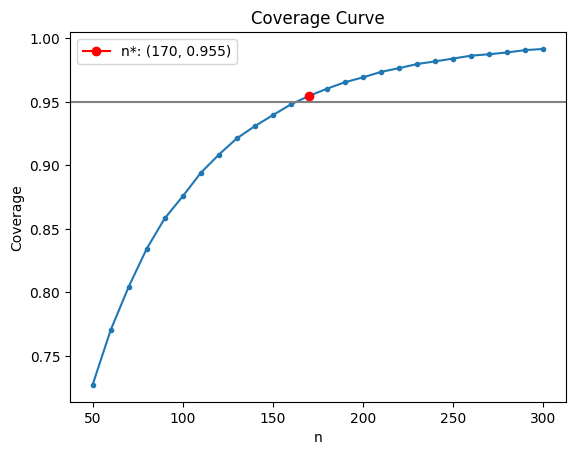

In [52]:
rq3_coverage = rq3_gap_table[rq3_gap_table["tolerance"] == 0.25].groupby("n")["proportion"].mean()
rq3_n_star = find_n_star(rq3_gap_table, 0.25, 0.95)

plt.plot(rq3_coverage, marker="o", markersize=3)
plt.plot(rq3_n_star, rq3_coverage.loc[rq3_n_star], marker="o", color="red", label=f"n*: ({rq3_n_star}, {rq3_coverage.loc[rq3_n_star]:.3f})")
plt.axhline(y=0.95, color="gray")
plt.title("Coverage Curve")
plt.xlabel("n")
plt.ylabel("Coverage")

plt.legend()
plt.show()

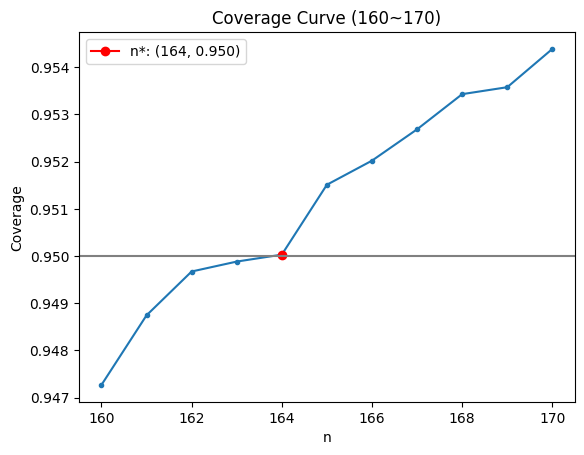

In [53]:
rq3_gap_table_fine = build_gap_table(rq3_df, range(rq3_n_star - 10, rq3_n_star + 1), seed=seed)
rq3_coverage_fine = rq3_gap_table_fine.groupby("n")["proportion"].mean()
rq3_n_star_fine = find_n_star(rq3_gap_table_fine, 0.25, 0.95)

plt.plot(rq3_coverage_fine, marker="o", markersize=3)
plt.plot(rq3_n_star_fine, rq3_coverage_fine.loc[rq3_n_star_fine], marker="o", color="red", label=f"n*: ({rq3_n_star_fine}, {rq3_coverage_fine.loc[rq3_n_star_fine]:.3f})")
plt.axhline(y=0.95, color="gray")
plt.title(f"Coverage Curve ({rq3_n_star - 10}~{rq3_n_star})")
plt.xlabel("n")
plt.ylabel("Coverage")

plt.legend()
plt.show()

## 5.3 Employers and Reviews Covered

In [54]:
# Count reviews per employer in each group
rq3_counts = df.groupby("firm_id")["former"].agg(n_former="sum", n_total="size")
rq3_counts["n_current"] = rq3_counts["n_total"] - rq3_counts["n_former"]
rq3_counts["n"] = rq3_counts[["n_former", "n_current"]].min(axis=1)

enough = rq3_counts["n"] >= rq3_n_star
rq3_employers_pct = enough.mean() * 100
rq3_reviews_pct = rq3_counts.loc[enough, "n_total"].sum() / rq3_counts["n_total"].sum() * 100

print(f"Employers with at least {rq3_n_star} reviews in both groups: {enough.sum():,} ({rq3_employers_pct:.1f}%)")
print(f"Reviews held by those employers: {rq3_reviews_pct:.1f}%")
print(f"Supplement (n* = {rq3_n_star_fine} from the finer grid): {(rq3_counts["n"] >= rq3_n_star_fine).mean() * 100:.1f}% of employers")

Employers with at least 170 reviews in both groups: 1,943 (7.0%)
Reviews held by those employers: 81.0%
Supplement (n* = 164 from the finer grid): 7.2% of employers


## 5.4 Result

In [55]:
print(f"H3 - more than half of employers lack n* reviews: {rq3_employers_pct < 50} ({rq3_employers_pct:.1f}% have enough)")
print(f"n* (resampling): {rq3_n_star}, n* (normal approximation): {rq3_n_star_normal}, difference: {rq3_n_star - rq3_n_star_normal}")
print(f"Employers with at least {rq3_n_star_normal} reviews (normal approximation): {(rq3_counts["n"] >= rq3_n_star_normal).mean() * 100:.1f}%")

H3 - more than half of employers lack n* reviews: True (7.0% have enough)
n* (resampling): 170, n* (normal approximation): 183, difference: -13
Employers with at least 183 reviews (normal approximation): 6.7%


## 5.5 Sensitivity Analysis

In [56]:
conditions = [(0.20, 0.95), (0.25, 0.95), (0.30, 0.95), (0.25, 0.90)]
z = {0.95: 1.96, 0.90: 1.645}

rows = []
for tolerance, level in conditions:
    n_star = find_n_star(rq3_gap_table, tolerance, level)
    enough = rq3_counts["n"] >= n_star
    rows.append({
        "Tolerance": tolerance,
        "Level": level,
        "n* (Resampling)": n_star,
        "n* (Normal)": normal_n_star(rq3_sd_all, tolerance, z[level]),
        "Employers (%)": enough.mean() * 100 if pd.notna(n_star) else np.nan,
        "Reviews (%)": rq3_counts.loc[enough, "n_total"].sum() / rq3_counts["n_total"].sum() * 100 if pd.notna(n_star) else np.nan,
    })

rq3_sensitivity = pd.DataFrame(rows)
rq3_sensitivity.round({"Employers (%)": 1, "Reviews (%)": 1})

,Tolerance,Level,n* (Resampling),n* (Normal),Employers (%),Reviews (%)
0,0.20,0.95,260,286,5.1,75.0
1,0.25,0.95,170,183,7.0,81.0
2,0.30,0.95,120,127,9.0,85.2
3,0.25,0.90,120,129,9.0,85.2


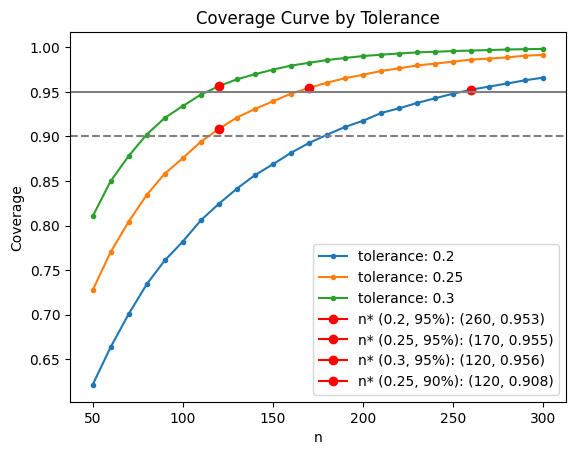

In [57]:
coverage = rq3_gap_table.groupby(["tolerance", "n"])["proportion"].mean().unstack("tolerance")

for tolerance in coverage.columns:
    plt.plot(coverage[tolerance], marker="o", markersize=3, label=f"tolerance: {tolerance}")

for tolerance, level in conditions:
    n_star = find_n_star(rq3_gap_table, tolerance, level)
    plt.plot(n_star, coverage.loc[n_star, tolerance], marker="o", color="red", label=f"n* ({tolerance}, {level:.0%}): ({n_star}, {coverage.loc[n_star, tolerance]:.3f})")

plt.axhline(y=0.95, color="gray")
plt.axhline(y=0.90, color="gray", linestyle="--")
plt.title("Coverage Curve by Tolerance")
plt.xlabel("n")
plt.ylabel("Coverage")

plt.legend()
plt.show()

# 6. Conclusion

## 6.1 Decision

| RQ | Hypothesis | Result | Compared with | Decision |
| :-- | :-- | :-- | :-- | :-- |
| RQ1 | H1 supported | −0.594 [−0.604, −0.583] | Pooled gap −0.500 (difference −0.094) | The pooled gap is enough |
| RQ2 | H2a, H2b supported | AUC 0.628 [0.622, 0.633] | Word count 0.502 (difference +0.126 [0.118, 0.133]) | TF-IDF adds signal beyond word count |
| RQ3 | H3 supported | n\* = 170, 7.0% of employers | Normal approximation n\* = 183, 6.7% of employers | The formula is enough |

### RQ1
Former employees rate their employer lower than current employees of the same employer, so H1 is supported. Across 8,539 employers, the average within-employer gap is −0.594 [−0.604, −0.583]. Its CI lies below 0, and its size is above the 0.25 we treat as meaningful. It differs from the pooled gap of −0.500 by only −0.094, so the pooled gap is enough, and employer mix, if anything, hides a small part of the gap. The gap stays negative for thresholds from 5 to 50 reviews per group (−0.620 to −0.513), although it shrinks as only larger employers remain. It is also negative in every tenure band, from −0.746 for less than one year to −0.410 for more than eight years, so differences in tenure do not explain it. The gap is a stable feature of former employees' reviews, not a product of employer mix or tenure.

### RQ2
Cons text helps distinguish former from current employees of the same employer and rating, so H2a and H2b are supported. On 2,194 test employers, TF-IDF reaches an AUC of 0.628 [0.622, 0.633], while word count stays at chance (0.502 [0.497, 0.507]). TF-IDF therefore adds signal beyond word count. However, 19 of the top 20 words for former employees are past-tense forms such as "was" and "were", and only "management" (rank 15) describes content. When we lemmatize verbs so that past and present forms match, the AUC falls by 0.035 [0.031, 0.039] to 0.593 [0.587, 0.598]. At the same time, "management" rises to rank 3, alongside words such as "cliquey", "downsize", "toxic" and "racist". About 27% of the signal above chance comes from tense, and the remaining 73% survives without it. Cons text separates former employees partly by tense and partly by what they write about, and "management" is the content word most strongly linked to former status.

### RQ3
Most employers do not have enough reviews to trust their gap, so H3 is supported. Resampling 333 reference employers gives n* = 170 reviews per group, 13 fewer than the normal approximation of 183 (164 on a finer grid). Only 7.0% of all employers have at least 170 former and 170 current reviews, although they hold 81.0% of reviews. With n* = 183 the share is 6.7%. Because both values lead to the same conclusion, the formula is sufficient, and it is slightly conservative. Across tolerances from 0.20 to 0.30 and levels of 90% and 95%, n* ranges from 120 to 260, and the share of employers stays between 5.1% and 9.0%. A reliable gap is available only for a small group of large employers.

## 6.2 Limitations

### Data
Our results describe associations among people who chose to post on Glassdoor. Reviewers decide whether to post and report their own status, so the reviews may not represent all employees, and some statuses may be wrong. We also cannot control who leaves an employer, so we cannot say that leaving causes lower ratings. The data cover Glassdoor employee reviews from 2020 onward, so the results may not hold for other platforms or periods.

### RQ1
The RQ1 checks depend on incomplete tenure data and on the review threshold. Tenure is missing for 39.7% of reviews, so the tenure-band gaps describe only reviewers who reported it. The size of the gap also moves by about 0.1 between thresholds of 5 and 50 reviews, even though the conclusion does not change. The direction of the gap is robust, but its exact size depends on these choices.

### RQ2
The AUC after lemmatization is an upper bound on the signal from content alone. Some status signals remain in the text. Examples are counterfactual forms ("can ve", "can have"), words that state status ("let go", "terminate", "former", "work there"), and a contraction gap: "it was" becomes "it be", but "it's" loses its "s" when the text is split into words. Lemmatization also merges forms unrelated to tense, such as "training" and "train". In addition, training uses all reviews and so is dominated by large employers, even though evaluation weights employers equally. We also tried only a linear TF-IDF model and one embedding model without fine-tuning. The signal from content alone may therefore be lower than 0.593.

### RQ3
The value of n* comes from the largest employers and may not transfer to smaller ones. We estimate it from the 333 employers with at least 1,000 reviews in each group, only 1.2% of employers, and then apply it to all employers. If ratings vary more at small employers, they need more than 170 reviews. The reference gap itself also has a margin of about ±0.11, resampling assumes that an employer's reviews represent its employees, and the 10-step grid limits the precision of n* (164 on a finer grid). The share of 7.0% should therefore be read as an approximation.

# Appendix

## Sentence Embedding

In [59]:
def embed_texts(texts: pd.Series, path: str, model: SentenceTransformer, n_chunks: int = 100) -> np.ndarray:
    """Embed texts, or load the saved embeddings if they already exist.

    Args:
        texts (pd.Series): Texts to embed
        path (str): Path of the .npy file to save or load
        model (SentenceTransformer): Embedding model
        n_chunks (int, optional): Number of chunks to encode, one progress bar step each

    Returns:
        np.ndarray: One embedding per text
    """
    if os.path.exists(path):
        return np.load(path)
    chunks = np.array_split(texts.to_numpy(), n_chunks)
    embd = np.vstack([
        model.encode(list(chunk), prompt_name="Classification", show_progress_bar=False)
        for chunk in tqdm(chunks, desc=os.path.basename(path))
    ])
    np.save(path, embd)
    return embd

se_model = SentenceTransformer("google/embeddinggemma-2", token=userdata.get("HF_TOKEN"), device="cuda")
se_model.max_seq_length = 512

X_train_se = embed_texts(train["cons_clean"], rq2_train_embd_path, se_model)
X_val_se = embed_texts(val["cons_clean"], rq2_val_embd_path, se_model)
X_test_se = embed_texts(test["cons_clean"], rq2_test_embd_path, se_model)

test_embd.npy: 100%|██████████| 100/100 [08:57<00:00,  5.38s/it]


In [60]:
val_auc_list_se = []

for c in c_list:
    lr_se = LogisticRegression(C=c, max_iter=1000, random_state=seed)
    model_se = lr_se.fit(X_train_se, train["former"])

    y_pred_se = model_se.predict_proba(X_val_se)[:, 1]
    val_auc = calculate_auc_score(val, y_pred_se)
    print(f"C: {c} Validation AUC: {val_auc:.3f}\n")
    val_auc_list_se.append([c, val_auc])

best_c_se, best_val_auc_se = max(val_auc_list_se, key=lambda x: x[1])
print(f"================================\nBest C: {best_c_se} Validation AUC: {best_val_auc_se:.3f}")

C: 0.01 Validation AUC: 0.604

C: 0.1 Validation AUC: 0.609

C: 1 Validation AUC: 0.606

C: 10 Validation AUC: 0.610

Best C: 10 Validation AUC: 0.610


In [61]:
lr_se = LogisticRegression(C=best_c_se, max_iter=1000, random_state=seed)
model_se = lr_se.fit(X_train_se, train["former"])

y_pred_se = model_se.predict_proba(X_test_se)[:, 1]
rq2_employer_auc_se = employer_auc(test, y_pred_se)
rq2_auc_se = rq2_employer_auc_se.mean()
rq2_lo_se, rq2_hi_se = bootstrap_ci(rq2_employer_auc_se, seed)
rq2_lo_diff_se, rq2_hi_diff_se = bootstrap_ci(rq2_employer_auc_se - rq2_employer_auc_tfidf, seed)

print(f"Sentence Embedding AUC: {rq2_auc_se:.3f} [{rq2_lo_se:.3f}, {rq2_hi_se:.3f}]")
print(f"Difference (Sentence Embedding - TF-IDF): {rq2_auc_se - rq2_auc_tfidf:.3f} [{rq2_lo_diff_se:.3f}, {rq2_hi_diff_se:.3f}]")

Sentence Embedding AUC: 0.605 [0.600, 0.610]
Difference (Sentence Embedding - TF-IDF): -0.022 [-0.027, -0.018]
